In [1]:
import torch
import os
# Set GPU
os.environ["CUDA_VISIBLE_DEVICES"] = "2"  # Select the GPU index
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
from scipy.special import comb
import numpy as np
import math
from opt_einsum import contract
from torch.autograd import Variable
from reed_muller_modules.hadamard import *
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import _LRScheduler, OneCycleLR
import time
from scipy.io import savemat
import pickle
from reed_muller_modules.reedmuller_codebook import *
from itertools import combinations
from scipy.signal import savgol_filter


Using device: cuda
CUDA version of Hadamard transform isn't installed. Will use Pytorch's version, which is much slower.


# Helper functions

In [2]:
def repetition_code_matrices(device, m=8):
    M_dict = {}
    for i in range(1, m):
        M_dict[i] = torch.ones(1, 2**i).to(device)
    return M_dict

def numpy_to_torch(tensor):
    return torch.from_numpy(tensor).float()

def first_order_encoder_Plotkin(msg_bits, order_of_RM1):
    repetition_M_dict = repetition_code_matrices(device, order_of_RM1)
    u_level0 = msg_bits[:, 0:1]
    v_level0 = msg_bits[:, 1:2]
    
    for i in range(2, order_of_RM1+1):
        u_level0 = torch.cat([u_level0, u_level0 * v_level0], dim=1)
        v_level0 = msg_bits[:, i:i+1].mm(repetition_M_dict[i-1])
    u_levelm = torch.cat([u_level0, u_level0 * v_level0], dim=1)
    
    return u_levelm

def generate_indices(all_msg_bits):
    # Get the number of bits and total number of messages
    num_bits = all_msg_bits.shape[1]
    
    # Initialize the indices tensors
    MinusOneIdx = []
    PlusOneIdx = []
    
    # For each bit position
    for i in range(num_bits):
        # Find indices where the bit is -1 and 1
        minus_one = torch.where(all_msg_bits[:, i] == -1)[0]
        plus_one = torch.where(all_msg_bits[:, i] == 1)[0]
        
        MinusOneIdx.append(minus_one)
        PlusOneIdx.append(plus_one)
    
    # Convert lists to tensors
    MinusOneIdx = torch.stack(MinusOneIdx).to(all_msg_bits.device)
    PlusOneIdx = torch.stack(PlusOneIdx).to(all_msg_bits.device)
    
    return MinusOneIdx, PlusOneIdx

def snr_db2sigma(train_snr):
    return 10**(-train_snr*1.0/20)/math.sqrt(2)

def log_sum_exp1(LLR_vector):
    sum_vector = LLR_vector.sum(dim=1, keepdim=True)
    sum_concat = torch.cat([sum_vector, torch.zeros_like(sum_vector)], dim=1)
    return torch.logsumexp(sum_concat, dim=1) - torch.logsumexp(LLR_vector, dim=1) 

def bin_array(num, m):
    """Convert a positive integer num into an m-bit bit vector"""
    return np.array(list(np.binary_repr(num).zfill(m))).astype(np.float32).reshape(-1)

def RM_mm_SoftMAP_decoder(LLR, RM_mm_codebook_PlusOne, RM_mm_codebook_MinusOne):
    max_PlusOne, _ = torch.max(contract('lk, ijk ->  lij', LLR, RM_mm_codebook_PlusOne), 2)
    max_MinusOne, _ = torch.max(contract('lk, ijk ->  lij', LLR, RM_mm_codebook_MinusOne), 2)
    
    return max_PlusOne - max_MinusOne

def first_order_Mul_matrices(device, m=8):
    Mul_Ind_Zero_dict, Mul_Ind_One_dict = {}, {}
    
    for i in range(1, m):
        # Loading the Mul_matrices
        try:
            Mul_Ind_Zero_dict[i] = Variable(torch.load(f'./data/{i}/Mul_this_matrix_Ind_Zero.pt')).to(device)
            Mul_Ind_One_dict[i] = Variable(torch.load(f'./data/{i}/Mul_this_matrix_Ind_One.pt')).to(device)
        except:
            print(f"Warning: Could not load matrices for m={i}. Please make sure the data files exist.")
    
    return Mul_Ind_Zero_dict, Mul_Ind_One_dict

def first_order_generator_matrices(device, m=8):
    G_dict = {}
    for i in range(1, m):
        RM_Class = ReedMuller(1, i if i>0 else 1)
        Generator_Matrix = numpy_to_torch(RM_Class.Generator_Matrix[:, ::-1].copy())
        G_dict[i] = Generator_Matrix.to(device)
    return G_dict

def power_constraint(codewords, gnet_top, power_constraint_type, training_mode):
    if power_constraint_type == 'hard_power_block':
        return F.normalize(codewords, p=2, dim=1)*np.sqrt(codewords.shape[1])
    else: # 'hard_power_bit'
        return codewords/codewords.abs()

def llr_info_bits(hadamard_transform_llr, order_of_RM1, Mul_Ind_Zero_dict, Mul_Ind_One_dict): 
    max_1, _ = hadamard_transform_llr.max(1, keepdim=True)
    min_1, _ = hadamard_transform_llr.min(1, keepdim=True)
    LLR_zero_column = max_1 + min_1 

    max_zero, _ = torch.max(contract('ij, kj ->  ikj', hadamard_transform_llr.abs(), Mul_Ind_Zero_dict[order_of_RM1]), 2)
    max_one, _ = torch.max(contract('ij, kj ->  ikj', hadamard_transform_llr.abs(), Mul_Ind_One_dict[order_of_RM1]), 2)
    LLR_remaining = max_zero - max_one
    return torch.cat([LLR_zero_column, LLR_remaining], dim=1)

def FirstOrder_SoftFHT_InfoBits_decoder(llr, order_of_RM1, Mul_Ind_Zero_dict, Mul_Ind_One_dict):
    hadamard_transform_llr = hadamard_transform_torch(llr)  # shape (batch_size, 2^m)
    return llr_info_bits(hadamard_transform_llr, order_of_RM1, Mul_Ind_Zero_dict, Mul_Ind_One_dict)

def errors_ber(y_true, y_pred):
    y_true = y_true.view(y_true.shape[0], -1, 1)
    y_pred = y_pred.view(y_pred.shape[0], -1, 1)
    myOtherTensor = torch.ne(torch.round(y_true), torch.round(y_pred)).float()
    res = sum(sum(myOtherTensor))/(myOtherTensor.shape[0]*myOtherTensor.shape[1])
    return res

def errors_bler(y_true, y_pred):
    y_true = y_true.view(y_true.shape[0], -1, 1)
    y_pred = y_pred.view(y_pred.shape[0], -1, 1)
    decoded_bits = torch.round(y_pred).cpu()
    X_test = torch.round(y_true).cpu()
    tp0 = (abs(decoded_bits-X_test)).view([X_test.shape[0],X_test.shape[1]])
    tp0 = tp0.detach().cpu().numpy()
    bler_err_rate = sum(np.sum(tp0,axis=1)>0)*1.0/(X_test.shape[0])
    return bler_err_rate


# Improved Neural network models with dropout

In [3]:
class g_Full(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, dropout_rate=0.1):
        super(g_Full, self).__init__()
        
        self.input_size = input_size
        self.half_input_size = int(input_size/2)
        self.hidden_size = hidden_size
        self.output_size = output_size
        
        self.fc1 = nn.Linear(self.input_size, self.hidden_size, bias=True)
        self.fc2 = nn.Linear(self.hidden_size, self.hidden_size, bias=True)
        self.fc3 = nn.Linear(self.hidden_size, self.hidden_size, bias=True)
        self.fc4 = nn.Linear(self.hidden_size, self.output_size, bias=True)
        
        self.dropout = nn.Dropout(dropout_rate)
        self.skip_scale = nn.Parameter(torch.tensor(0.1))  # Learnable skip connection scaling
        
    def forward(self, y):
        x = F.selu(self.fc1(y))
        x = self.dropout(x)
        x = F.selu(self.fc2(x))
        x = self.dropout(x)
        x = F.selu(self.fc3(x))
        x = self.dropout(x)
        x = self.fc4(x) + self.skip_scale * y[:, :, :self.half_input_size]*y[:,:, self.half_input_size:]
        return x

class f_Full(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, dropout_rate=0.1):
        super(f_Full, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        
        self.fc1 = nn.Linear(self.input_size, self.hidden_size, bias=True)
        self.fc2 = nn.Linear(self.hidden_size, self.hidden_size, bias=True)
        self.fc3 = nn.Linear(self.hidden_size, self.hidden_size, bias=True)
        self.fc4 = nn.Linear(self.hidden_size, self.output_size, bias=True)
        
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, y):
        x = F.selu(self.fc1(y))
        x = self.dropout(x)
        x = F.selu(self.fc2(x))
        x = self.dropout(x)
        x = F.selu(self.fc3(x))
        x = self.dropout(x)
        x = self.fc4(x)
        return x

# Improved weight initialization
def improved_weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        m.weight.data.normal_(0.0, 0.01)
    elif classname.find('BatchNorm') != -1:
        m.weight.data.normal_(0.0, 0.01)
        m.bias.data.fill_(0)
    elif classname.find('Linear') != -1:
        # Initialize close to zero for better initial behavior
        m.weight.data.normal_(0.0, 0.01)
        m.bias.data.fill_(0)

def rm_encoder_plotkin(msg_bits, r, m):
    if r == 0:
        out = msg_bits.repeat(1, 2**m)
        return out
    elif r == 1:
        # Create a new tensor with the desired arrangement
        rearranged_msg_bits = torch.cat([
            msg_bits[:, 0:1],  # Keep the first element
            msg_bits[:, 1:].flip(1)  # Flip the rest of the elements
        ], dim=1)
        out = first_order_encoder_Plotkin(rearranged_msg_bits.to(device), m)
        return out
    elif r == m:
        k1 = 2**(m-1)
        u = rm_encoder_plotkin(msg_bits[:,:k1], r-1, m-1)
        v = rm_encoder_plotkin(msg_bits[:,k1:], r-1, m-1)
        out = torch.cat([u, (u * v)], dim=1)
        return out
    else:
        k1 = int(sum([comb(m-1, i) for i in range(r+1)]))
        k2 = int(sum([comb(m-1, i) for i in range(r)]))
        u = rm_encoder_plotkin(msg_bits[:,:k1], r, m-1)
        v = rm_encoder_plotkin(msg_bits[:,k1:], r-1, m-1)
        out = torch.cat([u, (u * v)], dim=1)
        return out

def rm_encoder_plotkin_neural(msg_bits, r, m, gnet_dict, power_constraint_type='hard_power_block', training_mode='train'):
    """
    Reed-Muller encoder with neural network and power constraint only at final output.
    
    Args:
        msg_bits: Input message bits
        r: RM code parameter r
        m: RM code parameter m
        gnet_dict: Dictionary of neural networks
        power_constraint_type: Type of power constraint to apply
        training_mode: 'train' or 'test'
    """
    def encode_without_constraint(msg_bits, r, m):
        if r == 0:
            return msg_bits.repeat(1, 2**m)
        elif r == 1:
            # Create a new tensor with the desired arrangement
            rearranged_msg_bits = torch.cat([
                msg_bits[:, 0:1],  # Keep the first element
                msg_bits[:, 1:].flip(1)  # Flip the rest of the elements
            ], dim=1)
            return first_order_encoder_Plotkin(rearranged_msg_bits.to(device), m)
        elif r == m:
            k1 = 2**(m-1)
            u = encode_without_constraint(msg_bits[:,:k1], r-1, m-1)
            v = encode_without_constraint(msg_bits[:,k1:], r-1, m-1)
            return torch.cat([u, (u * v)], dim=1)
        else:
            k1 = int(sum([comb(m-1, i) for i in range(r+1)]))
            k2 = int(sum([comb(m-1, i) for i in range(r)]))
            u = encode_without_constraint(msg_bits[:,:k1], r, m-1)
            v = encode_without_constraint(msg_bits[:,k1:], r-1, m-1)
            
            # Apply neural network transform but don't constrain yet
            if m in gnet_dict:
                out = torch.cat([u, gnet_dict[m](torch.cat([u.unsqueeze(2), v.unsqueeze(2)], dim=2)).squeeze(2)], dim=1)
            else:
                # Fallback to standard Plotkin construction if no neural network is available for this level
                out = torch.cat([u, u * v], dim=1)
            
            return out
    
    # First encode without power constraint
    encoded = encode_without_constraint(msg_bits, r, m)
    
    # Apply power constraint only at the final output
    return power_constraint(encoded, None, power_constraint_type, training_mode)

def rm_decoder_dumer_neural(llr, r, m, fnet_dict, gnet_dict, Mul_Ind_Zero_dict, Mul_Ind_One_dict, m1=None):
    """
    Neural decoder for Reed-Muller codes.
    
    Args:
        llr: Log-likelihood ratios
        r: RM code parameter r
        m: RM code parameter m
        fnet_dict: Dictionary of neural decoder networks
        gnet_dict: Dictionary of neural encoder networks (needed for MAP decoding)
        Mul_Ind_Zero_dict, Mul_Ind_One_dict: Matrices for first-order decoding
        m1: Original m value for proper indexing in recursive calls
    """
    if m1 is None:
        m1 = m
        
    n = 2**m
    if r == 0:
        decoded_message = torch.tanh((torch.sum(llr, dim=1))/2).unsqueeze(1)
        return decoded_message
    elif r == 1:
        decoded_message = torch.tanh(FirstOrder_SoftFHT_InfoBits_decoder(llr, m, Mul_Ind_Zero_dict, Mul_Ind_One_dict)/2)
        return decoded_message
    elif r == m:
        k = sum(math.comb(m, i) for i in range(r+1))
        all_msg_bits_mm_leaf = []
        msg_length = k
        
        for i in range(2**k-1, -1, -1):
            bits = bin_array(i, msg_length)
            all_msg_bits_mm_leaf.append(bits*2-1)
            
        all_msg_bits_mm_leaf = torch.tensor(np.array(all_msg_bits_mm_leaf)).to(device)
        MinusOneIdx_mm_leaf, PlusOneIdx_mm_leaf = generate_indices(all_msg_bits_mm_leaf)
        
        with torch.no_grad():
            RM_mm_codebook = rm_encoder_plotkin_neural(all_msg_bits_mm_leaf, r, m, gnet_dict)
        
        RM_mm_codebook_PlusOne = RM_mm_codebook[PlusOneIdx_mm_leaf]
        RM_mm_codebook_MinusOne = RM_mm_codebook[MinusOneIdx_mm_leaf]
        
        decoded_message = torch.tanh(RM_mm_SoftMAP_decoder(llr, RM_mm_codebook_PlusOne, RM_mm_codebook_MinusOne)/2)
        return decoded_message
    else:
        # Split LLR into two halves
        llr_left = llr[:, :n//2]
        llr_right = llr[:, n//2:]

        # Use consistent indexing for decoder networks
        level = m1 - m + 1
        
        # Decode left child (v) only if we have the corresponding neural network
        if 2*level - 1 in fnet_dict:
            llr_v = fnet_dict[2*level - 1](torch.cat([llr_left.unsqueeze(2), llr_right.unsqueeze(2)], dim=2)).squeeze(2) + \
                  log_sum_exp1(torch.cat([llr_left.unsqueeze(2), llr_right.unsqueeze(2)], dim=2).permute(0, 2, 1))
        else:
            # Fallback to regular log-sum-exp operation
            llr_v = log_sum_exp1(torch.cat([llr_left.unsqueeze(2), llr_right.unsqueeze(2)], dim=2).permute(0, 2, 1))
            
        v_hat = rm_decoder_dumer_neural(llr_v, r-1, m-1, fnet_dict, gnet_dict, Mul_Ind_Zero_dict, Mul_Ind_One_dict, m1)
        v_c = rm_encoder_plotkin(v_hat.sign(), r-1, m-1)
        
        # Compute LLR for right child (u)
        if 2*level in fnet_dict:
            llr_u = fnet_dict[2*level](torch.cat([llr_left.unsqueeze(2), llr_right.unsqueeze(2), 
                                                 llr_v.unsqueeze(2), v_c.unsqueeze(2)], dim=2)).squeeze(2) + \
                  llr_left + v_c * llr_right
        else:
            # Fallback to standard operation
            llr_u = llr_left + v_c * llr_right
            
        u_hat = rm_decoder_dumer_neural(llr_u, r, m-1, fnet_dict, gnet_dict, Mul_Ind_Zero_dict, Mul_Ind_One_dict, m1)
        
        # Combine decoded bits
        decoded_message = torch.cat([u_hat, v_hat], dim=1)
        return decoded_message


In [4]:
def awgn_channel(codewords, snr):
    noise_sigma = snr_db2sigma(snr)
    standard_Gaussian = torch.randn_like(codewords)
    corrupted_codewords = codewords + noise_sigma * standard_Gaussian
    llrs = (2/(noise_sigma**2)) * corrupted_codewords
    return llrs

def save_model_state(gnet_dict, fnet_dict, path, prefix="", m_max=8):
    """Save encoder and decoder model states with verification."""
    # Ensure directory exists
    os.makedirs(os.path.join(path, 'Models'), exist_ok=True)
    
    # Save encoder state
    encoder_state = {}
    for i in range(3, m_max+1):
        if i in gnet_dict:
            encoder_state[f'g{i}'] = gnet_dict[i].state_dict()
            
    # Save decoder state
    decoder_state = {}
    for i in range(1, 2*m_max-3):
        if i in fnet_dict:
            decoder_state[f'f{i}'] = fnet_dict[i].state_dict()
    
    # Save states with verification
    encoder_path = f'{path}/Models/{prefix}Encoder_NN.pt'
    decoder_path = f'{path}/Models/{prefix}Decoder_NN.pt'
    
    torch.save(encoder_state, encoder_path)
    torch.save(decoder_state, decoder_path)
    
    # Verify saved files
    try:
        torch.load(encoder_path)
        torch.load(decoder_path)
        print(f"Successfully saved and verified models with prefix '{prefix}'")
    except Exception as e:
        print(f"Error verifying saved models: {e}")
        
    return encoder_state, decoder_state

def load_model_state(gnet_dict, fnet_dict, path, prefix="", m_max=8):
    """Load encoder and decoder model states with verification."""
    # Load saved states
    try:
        encoder_state = torch.load(f'{path}/Models/{prefix}Encoder_NN.pt')
        decoder_state = torch.load(f'{path}/Models/{prefix}Decoder_NN.pt')
    except FileNotFoundError as e:
        print(f"Error loading model files: {e}")
        return gnet_dict, fnet_dict
    
    # Load encoder weights with verification
    for i in range(3, m_max+1):
        if i in gnet_dict and f'g{i}' in encoder_state:
            try:
                gnet_dict[i].load_state_dict(encoder_state[f'g{i}'])
                gnet_dict[i].eval()
                print(f"Successfully loaded encoder g{i}")
            except Exception as e:
                print(f"Error loading encoder g{i}: {e}")
    
    # Load decoder weights with verification
    for i in range(1, 2*m_max-3):
        if i in fnet_dict and f'f{i}' in decoder_state:
            try:
                fnet_dict[i].load_state_dict(decoder_state[f'f{i}'])
                fnet_dict[i].eval()
                print(f"Successfully loaded decoder f{i}")
            except Exception as e:
                print(f"Error loading decoder f{i}: {e}")
    
    return gnet_dict, fnet_dict

def validate_submodule_transfer(small_model_dict, large_model_dict, r_small, m_small, r_large, m_large, test_batch_size=10):
    """Validates that submodules were correctly transferred by comparing outputs on test data."""
    print("Validating submodule transfer...")
    
    # Compute code dimensions
    k_small = sum(math.comb(m_small, i) for i in range(r_small+1))
    k_large = sum(math.comb(m_large, i) for i in range(r_large+1))
    
    # Generate test message
    with torch.no_grad():
        test_msg = 2*torch.randint(0, 2, (test_batch_size, k_small), dtype=torch.float32).to(device)-1
        
        # Get output from small model
        small_output = rm_encoder_plotkin_neural(test_msg, r_small, m_small, small_model_dict)
        
        # Create appropriate input for large model
        test_msg_large = torch.zeros(test_batch_size, k_large).to(device)
        # Place the small test message in the right location
        # This depends on the specific hierarchical structure
        # For this example, we'll assume small module maps to a specific section
        test_msg_large[:, :k_small] = test_msg
        
        # Get output from large model
        large_output = rm_encoder_plotkin_neural(test_msg_large, r_large, m_large, large_model_dict)
        
        # Compare outputs - specific comparison depends on where in the hierarchy the
        # small model should map to in the large model
        # For simplicity, we'll compare a section of the output
        error = torch.norm(small_output - large_output[:, :small_output.shape[1]])
        
        print(f"Submodule transfer validation error: {error.item()}")
        if error.item() > 1.0:
            print("WARNING: Large error in submodule transfer validation!")
            print("The pretrained weights may not be correctly applied.")
        else:
            print("Submodule transfer validation successful!")
            
        return error.item()

In [5]:



def train_ko_code(r, m, gnet_dict, fnet_dict, 
                  Mul_Ind_Zero_dict, Mul_Ind_One_dict,
                  batch_size=10000, small_batch_size=1000, 
                  hidden_size=64, num_epochs=300,
                  enc_train_iters=10, dec_train_iters=50,
                  enc_train_snr=1.0, dec_train_snr=0.0,
                  save_dir=None, freeze_submodules=False,
                  pretrained_levels=None, progressive_unfreeze=True):
    """
    Train a KO code with given parameters and progressive unfreezing
    
    Args:
        r, m: KO code parameters KO(m,r)
        gnet_dict, fnet_dict: Neural network dictionaries
        Mul_Ind_Zero_dict, Mul_Ind_One_dict: Matrices for first-order decoding
        batch_size, small_batch_size: Batch sizes for training
        hidden_size: Size of hidden layers in neural networks
        num_epochs: Number of training epochs
        enc_train_iters, dec_train_iters: Training iterations for encoder and decoder
        enc_train_snr, dec_train_snr: SNR values for encoder and decoder training
        save_dir: Directory to save models
        freeze_submodules: Whether to freeze pretrained submodules
        pretrained_levels: List of levels that use pretrained weights
        progressive_unfreeze: Whether to progressively unfreeze modules during training
        
    Returns:
        losses, bers: Training history
    """
    if save_dir is None:
        save_dir = f"./Results/KO({m},{r})"
    
    os.makedirs(save_dir, exist_ok=True)
    os.makedirs(os.path.join(save_dir, 'Models'), exist_ok=True)
    
    # Compute code dimension
    code_dim_k = sum(math.comb(m, i) for i in range(r+1))
    N = 2**m
    
    print(f"Training KO({m},{r}) code with dimension k={code_dim_k}, block length n={N}")
    print(f"Using batch_size={batch_size}, small_batch_size={small_batch_size}")
    print(f"Encoder SNR={enc_train_snr} dB, Decoder SNR={dec_train_snr} dB")
    
    # Unfreezing schedule for progressive unfreezing
    if progressive_unfreeze and freeze_submodules and pretrained_levels:
        unfreeze_epochs = []
        # Create unfreezing schedule
        for i, level in enumerate(pretrained_levels):
            unfreeze_epoch = int((i+1) * num_epochs / (len(pretrained_levels) + 1))
            unfreeze_epochs.append((unfreeze_epoch, level))
        print(f"Progressive unfreezing schedule: {unfreeze_epochs}")
    
    # Create encoder optimizer
    enc_params = []
    for i in range(3, m+1):
        if i in gnet_dict:
            # If we're freezing certain levels and this is a pretrained level
            if freeze_submodules and pretrained_levels and i in pretrained_levels:
                # Freeze the parameters by not adding them to the optimizer
                for param in gnet_dict[i].parameters():
                    param.requires_grad = False
                print(f"Freezing encoder g{i}")
            else:
                for param in gnet_dict[i].parameters():
                    param.requires_grad = True
                enc_params += list(gnet_dict[i].parameters())
                
    # Create decoder optimizer
    dec_params = []
    for i in range(1, 2*m-3):
        if i in fnet_dict:
            # If we're freezing certain levels and this level corresponds to a pretrained level
            level = (i + 1) // 2  # Convert decoder index to encoder level
            m_level = m - level + 1  # Convert level to m value
            
            if freeze_submodules and pretrained_levels and m_level in pretrained_levels:
                # Freeze the parameters
                for param in fnet_dict[i].parameters():
                    param.requires_grad = False
                print(f"Freezing decoder f{i} (corresponds to level m={m_level})")
            else:
                for param in fnet_dict[i].parameters():
                    param.requires_grad = True
                dec_params += list(fnet_dict[i].parameters())
    
    # Create optimizers with appropriate learning rates
    enc_optimizer = optim.Adam(enc_params, lr=2e-4, betas=(0.9, 0.98), eps=1e-9)
    dec_optimizer = optim.Adam(dec_params, lr=2e-4, betas=(0.9, 0.98), eps=1e-9)
    
    # Create improved schedulers - OneCycleLR instead of WarmupCosineAnnealing
    enc_scheduler = OneCycleLR(
        enc_optimizer,
        max_lr=2e-4,
        total_steps=num_epochs * enc_train_iters,
        pct_start=0.3,  # 30% of training is warmup
        div_factor=25.0,  # initial_lr = max_lr/25
        final_div_factor=1000.0  # min_lr = initial_lr/10000
    )
    
    dec_scheduler = OneCycleLR(
        dec_optimizer,
        max_lr=2e-4,
        total_steps=num_epochs * dec_train_iters,
        pct_start=0.3,
        div_factor=25.0,
        final_div_factor=1000.0
    )
    
    # Loss function
    criterion = nn.BCEWithLogitsLoss()
    
    # Training history
    losses = []
    bers = []
    best_loss = float('inf')
    patience = 20  # Early stopping patience
    patience_counter = 0
    
    # Save initial model
    save_model_state(gnet_dict, fnet_dict, save_dir, prefix="initial_", m_max=m)
    
    # Initialize gradual unfreezing tracker
    unfrozen_levels = set()
    
    # Create validation set for monitoring progress
    val_msg_bits = 2*torch.randint(0, 2, (1000, code_dim_k), dtype=torch.float32).to(device)-1
    
    try:
        for epoch in range(num_epochs):
            start_time = time.time()
            
            # Check if we need to unfreeze any levels according to schedule
            if progressive_unfreeze and freeze_submodules and pretrained_levels:
                for unfreeze_epoch, level in unfreeze_epochs:
                    if epoch == unfreeze_epoch and level not in unfrozen_levels:
                        print(f"Unfreezing level m={level} (epoch {epoch})")
                        
                        # Unfreeze encoder
                        if level in gnet_dict:
                            for param in gnet_dict[level].parameters():
                                param.requires_grad = True
                            enc_params.extend(list(gnet_dict[level].parameters()))
                        
                        # Unfreeze corresponding decoders
                        for i in range(1, 2*m-3):
                            decoder_level = (i + 1) // 2
                            m_decoder_level = m - decoder_level + 1
                            if m_decoder_level == level and i in fnet_dict:
                                for param in fnet_dict[i].parameters():
                                    param.requires_grad = True
                                dec_params.extend(list(fnet_dict[i].parameters()))
                        
                        # Recreate optimizers with updated parameter lists
                        enc_optimizer = optim.Adam(enc_params, lr=1e-4, betas=(0.9, 0.98), eps=1e-9)
                        dec_optimizer = optim.Adam(dec_params, lr=1e-4, betas=(0.9, 0.98), eps=1e-9)
                        
                        # Create new schedulers
                        remaining_epochs = num_epochs - epoch
                        enc_scheduler = OneCycleLR(
                            enc_optimizer,
                            max_lr=1e-4,  # Lower max learning rate for fine tuning
                            total_steps=remaining_epochs * enc_train_iters,
                            pct_start=0.2,  # 20% of remaining training for warmup
                            div_factor=25.0,
                            final_div_factor=10000.0
                        )
                        
                        dec_scheduler = OneCycleLR(
                            dec_optimizer,
                            max_lr=1e-4,
                            total_steps=remaining_epochs * dec_train_iters,
                            pct_start=0.2,
                            div_factor=25.0,
                            final_div_factor=10000.0
                        )
                        
                        # Add to unfrozen levels
                        unfrozen_levels.add(level)
            
            # Generate batch of message bits
            msg_bits_large_batch = 2*torch.randint(0, 2, (batch_size, code_dim_k), 
                                                  dtype=torch.float32).to(device)-1
            
            num_small_batches = batch_size // small_batch_size
            epoch_loss = 0
            epoch_ber = 0
            
            # Train decoder
            for _ in range(dec_train_iters):
                dec_optimizer.zero_grad()
                decoder_loss = 0
                
                for i in range(num_small_batches):
                    # Get mini-batch
                    start, end = i*small_batch_size, (i+1)*small_batch_size
                    msg_bits = msg_bits_large_batch[start:end]
                    
                    # Forward pass through encoder
                    transmit_codewords = rm_encoder_plotkin_neural(msg_bits, r, m, gnet_dict)
                    
                    # Add noise
                    corrupted_codewords = awgn_channel(transmit_codewords, dec_train_snr)
                    
                    # Decode
                    decoded_message = rm_decoder_dumer_neural(corrupted_codewords, r, m, fnet_dict, gnet_dict, 
                                                            Mul_Ind_Zero_dict, Mul_Ind_One_dict)
                    
                    # Calculate loss
                    loss = criterion(0.5*decoded_message+0.5, 0.5*msg_bits+0.5) / num_small_batches
                    decoder_loss += loss.item()
                    
                    # Backward pass
                    loss.backward()
                
                # Clip gradients to prevent explosion
                torch.nn.utils.clip_grad_norm_(dec_params, 1.0)
                
                # Update decoder weights
                dec_optimizer.step()
                dec_scheduler.step()
            
            # Train encoder
            for _ in range(enc_train_iters):
                enc_optimizer.zero_grad()
                encoder_loss = 0
                
                for i in range(num_small_batches):
                    # Get mini-batch
                    start, end = i*small_batch_size, (i+1)*small_batch_size
                    msg_bits = msg_bits_large_batch[start:end]
                    
                    # Forward pass through encoder
                    transmit_codewords = rm_encoder_plotkin_neural(msg_bits, r, m, gnet_dict)
                    
                    # Add noise
                    corrupted_codewords = awgn_channel(transmit_codewords, enc_train_snr)
                    
                    # Decode
                    decoded_message = rm_decoder_dumer_neural(corrupted_codewords, r, m, fnet_dict, gnet_dict, 
                                                            Mul_Ind_Zero_dict, Mul_Ind_One_dict)
                    
                    # Calculate loss
                    loss = criterion(0.5*decoded_message+0.5, 0.5*msg_bits+0.5) / num_small_batches
                    encoder_loss += loss.item()
                    
                    # Calculate BER
                    ber = errors_ber(msg_bits, decoded_message.sign())
                    epoch_ber = ber.item()
                    
                    # Backward pass
                    loss.backward()
                    
                # Clip gradients
                torch.nn.utils.clip_grad_norm_(enc_params, 1.0)
                
                # Update encoder weights
                enc_optimizer.step()
                enc_scheduler.step()
                epoch_loss = encoder_loss
            
            # Evaluate on validation set
            with torch.no_grad():
                val_codewords = rm_encoder_plotkin_neural(val_msg_bits, r, m, gnet_dict)
                val_corrupted = awgn_channel(val_codewords, enc_train_snr)
                val_decoded = rm_decoder_dumer_neural(val_corrupted, r, m, fnet_dict, gnet_dict, 
                                                    Mul_Ind_Zero_dict, Mul_Ind_One_dict)
                val_loss = criterion(0.5*val_decoded+0.5, 0.5*val_msg_bits+0.5).item()
                val_ber = errors_ber(val_msg_bits, val_decoded.sign()).item()
            
            # Store results
            losses.append(val_loss)
            bers.append(val_ber)
            
            # Print progress with more detailed information
            print(f'[{epoch+1}/{num_epochs}] Train Loss: {epoch_loss:.6f} Val Loss: {val_loss:.6f} Val BER: {val_ber:.6f}')
            print(f"Time for one epoch: {(time.time() - start_time)/60:.4f} minutes")
            print(f"Encoder LR: {enc_optimizer.param_groups[0]['lr']:.6f}, Decoder LR: {dec_optimizer.param_groups[0]['lr']:.6f}")
            
            # Check for early stopping
            if val_loss < best_loss:
                best_loss = val_loss
                patience_counter = 0
                # Save best model
                save_model_state(gnet_dict, fnet_dict, save_dir, prefix=f"best_", m_max=m)
            else:
                patience_counter += 1
                
            # Save model at regular intervals
            if (epoch + 1) % 10 == 0 or epoch == 0:
                save_model_state(gnet_dict, fnet_dict, save_dir, prefix=f"epoch_{epoch+1}_", m_max=m)
            
#             # Early stopping
#             if patience_counter >= patience:
#                 print(f"Early stopping at epoch {epoch+1} as validation loss has not improved for {patience} epochs")
#                 break
                
    except KeyboardInterrupt:
        print("Training interrupted!")
        
    # Save final model
    save_model_state(gnet_dict, fnet_dict, save_dir, prefix="final_", m_max=m)
    
    # Plot training curves with semilogy
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.semilogy(losses)
    plt.title('Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True, which="both", ls="-", alpha=0.6)

    plt.subplot(1, 2, 2)
    plt.semilogy(bers)
    plt.title('Validation BER')
    plt.xlabel('Epoch')
    plt.ylabel('BER')
    plt.grid(True, which="both", ls="-", alpha=0.6)

    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, 'training_curves.png'))
    
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, 'training_curves.png'))
    
    # Save training history
    np.savez(os.path.join(save_dir, 'training_history.npz'), 
             losses=np.array(losses), 
             bers=np.array(bers))
    
    return losses, bers




In [6]:
def hierarchical_training():
    """
    Implements hierarchical training for KO(9,3):
    1. Check if KO(4,3) and KO(4,2) pretrained weights exist
    2. If they don't exist, train them
    3. Train KO(9,3) using pretrained weights from KO(4,3) and KO(4,2)
    """
    print("Starting hierarchical KO code training for KO(9,3)...")
    
    # Common parameters
    hidden_size = 120
    dropout_rate = 0.1
    
    # Load matrices for decoding
    print("Loading matrices for decoding...")
    Mul_Ind_Zero_dict, Mul_Ind_One_dict = first_order_Mul_matrices(device, 10)  # Up to m=9 (so 10 total)
    
    # Define submodule paths
    save_dir_small1 = "./Results/KO(4,3)_improved"
    save_dir_small2 = "./Results/KO(4,2)_improved"
    
    # Check if submodule weights already exist
    submodule1_exists = os.path.exists(f'{save_dir_small1}/Models/final_Encoder_NN.pt')
    submodule2_exists = os.path.exists(f'{save_dir_small2}/Models/final_Encoder_NN.pt')
    
    r_small1, m_small1 = 3, 4
    r_small2, m_small2 = 2, 4
    
    # Initialize submodule dictionaries
    gnet_dict_small1 = {}
    fnet_dict_small1 = {}
    gnet_dict_small2 = {}
    fnet_dict_small2 = {}
    
    #################################################
    # Step 1: Check/Train KO(4,3)
    #################################################
    if not submodule1_exists:
        k_small1 = sum(math.comb(m_small1, i) for i in range(r_small1+1))
        print(f"\n\n======= Starting KO({m_small1},{r_small1}) training =======")
        print(f"Code parameters: k={k_small1}, n={2**m_small1}")
        
        # Initialize networks
        for i in range(3, m_small1+1):
            gnet_dict_small1[i] = g_Full(2, hidden_size, 1, dropout_rate).to(device)
            gnet_dict_small1[i].apply(improved_weights_init)
            
        for i in range(1, 2*m_small1-3):
            fnet_dict_small1[i] = f_Full(2 if i % 2 == 1 else 4, hidden_size, 1, dropout_rate).to(device)
            fnet_dict_small1[i].apply(improved_weights_init)
        
        # Train
        train_ko_code(
            r=r_small1, 
            m=m_small1, 
            gnet_dict=gnet_dict_small1, 
            fnet_dict=fnet_dict_small1,
            Mul_Ind_Zero_dict=Mul_Ind_Zero_dict, 
            Mul_Ind_One_dict=Mul_Ind_One_dict,
            batch_size=4000,
            small_batch_size=1000,
            hidden_size=hidden_size,
            num_epochs=200,
            enc_train_iters=50,
            dec_train_iters=500,
            enc_train_snr=0.0,
            dec_train_snr=-1.0,
            save_dir=save_dir_small1
        )
        print(f"KO({m_small1},{r_small1}) training completed!")
    else:
        print(f"KO({m_small1},{r_small1}) pretrained weights already exist. Skipping training.")
    
    #################################################
    # Step 2: Check/Train KO(4,2)
    #################################################
    if not submodule2_exists:
        k_small2 = sum(math.comb(m_small2, i) for i in range(r_small2+1))
        print(f"\n\n======= Starting KO({m_small2},{r_small2}) training =======")
        print(f"Code parameters: k={k_small2}, n={2**m_small2}")
        
        # Initialize networks
        for i in range(3, m_small2+1):
            gnet_dict_small2[i] = g_Full(2, hidden_size, 1, dropout_rate).to(device)
            gnet_dict_small2[i].apply(improved_weights_init)
            
        for i in range(1, 2*m_small2-3):
            fnet_dict_small2[i] = f_Full(2 if i % 2 == 1 else 4, hidden_size, 1, dropout_rate).to(device)
            fnet_dict_small2[i].apply(improved_weights_init)
        
        # Train
        train_ko_code(
            r=r_small2, 
            m=m_small2, 
            gnet_dict=gnet_dict_small2, 
            fnet_dict=fnet_dict_small2,
            Mul_Ind_Zero_dict=Mul_Ind_Zero_dict, 
            Mul_Ind_One_dict=Mul_Ind_One_dict,
            batch_size=4000, 
            small_batch_size=1000,
            hidden_size=hidden_size,
            num_epochs=200,
            enc_train_iters=50,
            dec_train_iters=500,
            enc_train_snr=0.0,
            dec_train_snr=-1.0,
            save_dir=save_dir_small2
        )
        print(f"KO({m_small2},{r_small2}) training completed!")
    else:
        print(f"KO({m_small2},{r_small2}) pretrained weights already exist. Skipping training.")
    
    #################################################
    # Step 3: Train KO(9,3) with improved hierarchical approach
    #################################################
    r_large, m_large = 3, 9
    k_large = sum(math.comb(m_large, i) for i in range(r_large+1))
    print(f"\n\n======= Starting KO({m_large},{r_large}) hierarchical training =======")
    print(f"Code parameters: k={k_large}, n={2**m_large}")
    
    # Create model dictionaries for the large code
    gnet_dict_large = {}
    fnet_dict_large = {}
    
    # Initialize all networks with improved initializations
    for i in range(3, m_large+1):
        gnet_dict_large[i] = g_Full(2, hidden_size, 1, dropout_rate).to(device)
        gnet_dict_large[i].apply(improved_weights_init)
        
    for i in range(1, 2*m_large-3):
        fnet_dict_large[i] = f_Full(2 if i % 2 == 1 else 4, hidden_size, 1, dropout_rate).to(device)
        fnet_dict_large[i].apply(improved_weights_init)
    
    # Load pretrained weights for submodules
    
    # First, load all available weights from KO(4,3)
    encoder_state_small1 = torch.load(f'{save_dir_small1}/Models/best_Encoder_NN.pt')
    decoder_state_small1 = torch.load(f'{save_dir_small1}/Models/best_Decoder_NN.pt')
    
    # Then, load all available weights from KO(4,2)
    encoder_state_small2 = torch.load(f'{save_dir_small2}/Models/best_Encoder_NN.pt')
    decoder_state_small2 = torch.load(f'{save_dir_small2}/Models/best_Decoder_NN.pt')
    
    # Transfer weights from KO(4,3) to the appropriate submodules of KO(9,3)
    # For KO(9,3), we would use KO(4,3) weights at level m=5
    if 'g4' in encoder_state_small1:
        gnet_dict_large[5].load_state_dict(encoder_state_small1['g4'])
        print("Loaded KO(4,3) encoder g4 weights into g5")
    
    # At level m=6 of KO(9,3), we need the KO(4,2) encoder
    if 'g4' in encoder_state_small2:
        gnet_dict_large[6].load_state_dict(encoder_state_small2['g4'])
        print("Loaded KO(4,2) encoder g4 weights into g6")
        
    # Similarly for the decoders - these mappings need to be adjusted for m=9
    for i, j in zip([9, 10], [1, 2]):  # Map KO(4,3) decoder indices to KO(9,3)
        key = f'f{j}'
        if key in decoder_state_small1:
            fnet_dict_large[i].load_state_dict(decoder_state_small1[key])
            print(f"Loaded KO(4,3) decoder {key} weights into f{i}")
            
    for i, j in zip([7, 8], [1, 2]):  # Map KO(4,2) decoder indices to KO(9,3)
        key = f'f{j}'
        if key in decoder_state_small2:
            fnet_dict_large[i].load_state_dict(decoder_state_small2[key])
            print(f"Loaded KO(4,2) decoder {key} weights into f{i}")
    
    # Create save directory for the large code
    save_dir_large = f"./Results/KO({m_large},{r_large})_hierarchical_improved"
    
    # Train hierarchically with improved approach - single stage with progressive unfreezing
    train_ko_code(
        r=r_large, 
        m=m_large, 
        gnet_dict=gnet_dict_large, 
        fnet_dict=fnet_dict_large,
        Mul_Ind_Zero_dict=Mul_Ind_Zero_dict, 
        Mul_Ind_One_dict=Mul_Ind_One_dict,
        batch_size=4000,  
        small_batch_size=1000,
        hidden_size=hidden_size,
        num_epochs=300,  
        enc_train_iters=20,
        dec_train_iters=100,
        enc_train_snr=-1.0,
        dec_train_snr=-2.0,
        save_dir=save_dir_large,
        freeze_submodules=True,
        pretrained_levels=[5, 6],  # These levels use pretrained weights
        progressive_unfreeze=True  # Progressively unfreeze during training
    )
    
    print("Hierarchical training for KO(9,3) complete!")

Starting hierarchical KO code training for KO(9,3)...
Loading matrices for decoding...
KO(4,3) pretrained weights already exist. Skipping training.
KO(4,2) pretrained weights already exist. Skipping training.


======= Starting KO(9,3) hierarchical training =======
Code parameters: k=130, n=512
Loaded KO(4,3) encoder g4 weights into g5
Loaded KO(4,2) encoder g4 weights into g6
Loaded KO(4,3) decoder f1 weights into f9
Loaded KO(4,3) decoder f2 weights into f10
Loaded KO(4,2) decoder f1 weights into f7
Loaded KO(4,2) decoder f2 weights into f8
Training KO(9,3) code with dimension k=130, block length n=512
Using batch_size=4000, small_batch_size=1000
Encoder SNR=-1.0 dB, Decoder SNR=-2.0 dB
Progressive unfreezing schedule: [(100, 5), (200, 6)]
Freezing encoder g5
Freezing encoder g6
Freezing decoder f7 (corresponds to level m=6)
Freezing decoder f8 (corresponds to level m=6)
Freezing decoder f9 (corresponds to level m=5)
Freezing decoder f10 (corresponds to level m=5)
Successfully saved 

[39/300] Train Loss: 0.621646 Val Loss: 0.621222 Val BER: 0.237808
Time for one epoch: 2.2433 minutes
Encoder LR: 0.000084, Decoder LR: 0.000084
Successfully saved and verified models with prefix 'best_'
[40/300] Train Loss: 0.598009 Val Loss: 0.596949 Val BER: 0.188600
Time for one epoch: 2.2533 minutes
Encoder LR: 0.000087, Decoder LR: 0.000087
Successfully saved and verified models with prefix 'best_'
Successfully saved and verified models with prefix 'epoch_40_'
[41/300] Train Loss: 0.579190 Val Loss: 0.577397 Val BER: 0.148931
Time for one epoch: 2.2474 minutes
Encoder LR: 0.000091, Decoder LR: 0.000091
Successfully saved and verified models with prefix 'best_'
[42/300] Train Loss: 0.573079 Val Loss: 0.572682 Val BER: 0.139585
Time for one epoch: 2.2465 minutes
Encoder LR: 0.000094, Decoder LR: 0.000094
Successfully saved and verified models with prefix 'best_'
[43/300] Train Loss: 0.571366 Val Loss: 0.572446 Val BER: 0.138592
Time for one epoch: 2.2418 minutes
Encoder LR: 0.00009

[87/300] Train Loss: 0.503160 Val Loss: 0.503533 Val BER: 0.000392
Time for one epoch: 2.2341 minutes
Encoder LR: 0.000199, Decoder LR: 0.000199
[88/300] Train Loss: 0.503899 Val Loss: 0.503481 Val BER: 0.000262
Time for one epoch: 2.2617 minutes
Encoder LR: 0.000200, Decoder LR: 0.000200
[89/300] Train Loss: 0.503717 Val Loss: 0.503467 Val BER: 0.000238
Time for one epoch: 2.2530 minutes
Encoder LR: 0.000200, Decoder LR: 0.000200
[90/300] Train Loss: 0.503875 Val Loss: 0.503583 Val BER: 0.000485
Time for one epoch: 2.2360 minutes
Encoder LR: 0.000200, Decoder LR: 0.000200
Successfully saved and verified models with prefix 'epoch_90_'
[91/300] Train Loss: 0.503376 Val Loss: 0.503350 Val BER: 0.000000
Time for one epoch: 2.2440 minutes
Encoder LR: 0.000200, Decoder LR: 0.000200
Successfully saved and verified models with prefix 'best_'
[92/300] Train Loss: 0.503639 Val Loss: 0.503586 Val BER: 0.000515
Time for one epoch: 2.2325 minutes
Encoder LR: 0.000200, Decoder LR: 0.000200
[93/300]

[140/300] Train Loss: 0.503398 Val Loss: 0.503459 Val BER: 0.000246
Time for one epoch: 2.2705 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
Successfully saved and verified models with prefix 'epoch_140_'
[141/300] Train Loss: 0.503101 Val Loss: 0.503670 Val BER: 0.000638
Time for one epoch: 2.2513 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
[142/300] Train Loss: 0.503501 Val Loss: 0.503453 Val BER: 0.000208
Time for one epoch: 2.2475 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
[143/300] Train Loss: 0.503371 Val Loss: 0.503634 Val BER: 0.000554
Time for one epoch: 2.2606 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
[144/300] Train Loss: 0.503468 Val Loss: 0.503968 Val BER: 0.001269
Time for one epoch: 2.2443 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
[145/300] Train Loss: 0.503623 Val Loss: 0.503402 Val BER: 0.000100
Time for one epoch: 2.2728 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
[146/300] Train Loss: 0.503447 Val Loss: 0.503425 Val BER: 0

[194/300] Train Loss: 0.503584 Val Loss: 0.503508 Val BER: 0.000323
Time for one epoch: 2.2726 minutes
Encoder LR: 0.000074, Decoder LR: 0.000074
[195/300] Train Loss: 0.502841 Val Loss: 0.503356 Val BER: 0.000000
Time for one epoch: 2.2736 minutes
Encoder LR: 0.000074, Decoder LR: 0.000074
[196/300] Train Loss: 0.503344 Val Loss: 0.503525 Val BER: 0.000377
Time for one epoch: 2.2455 minutes
Encoder LR: 0.000073, Decoder LR: 0.000073
[197/300] Train Loss: 0.503522 Val Loss: 0.503485 Val BER: 0.000262
Time for one epoch: 2.2751 minutes
Encoder LR: 0.000072, Decoder LR: 0.000072
[198/300] Train Loss: 0.503450 Val Loss: 0.503376 Val BER: 0.000054
Time for one epoch: 2.2426 minutes
Encoder LR: 0.000071, Decoder LR: 0.000071
[199/300] Train Loss: 0.503455 Val Loss: 0.503349 Val BER: 0.000000
Time for one epoch: 2.2439 minutes
Encoder LR: 0.000070, Decoder LR: 0.000070
[200/300] Train Loss: 0.503912 Val Loss: 0.503614 Val BER: 0.000577
Time for one epoch: 2.2444 minutes
Encoder LR: 0.000069,

[248/300] Train Loss: 0.503551 Val Loss: 0.503572 Val BER: 0.000462
Time for one epoch: 2.2469 minutes
Encoder LR: 0.000073, Decoder LR: 0.000073
[249/300] Train Loss: 0.503683 Val Loss: 0.503407 Val BER: 0.000108
Time for one epoch: 2.2667 minutes
Encoder LR: 0.000071, Decoder LR: 0.000071
[250/300] Train Loss: 0.503108 Val Loss: 0.503495 Val BER: 0.000292
Time for one epoch: 2.2512 minutes
Encoder LR: 0.000069, Decoder LR: 0.000069
Successfully saved and verified models with prefix 'epoch_250_'
[251/300] Train Loss: 0.503223 Val Loss: 0.503363 Val BER: 0.000038
Time for one epoch: 2.3103 minutes
Encoder LR: 0.000067, Decoder LR: 0.000067
[252/300] Train Loss: 0.503238 Val Loss: 0.503447 Val BER: 0.000200
Time for one epoch: 2.2840 minutes
Encoder LR: 0.000065, Decoder LR: 0.000065
[253/300] Train Loss: 0.503296 Val Loss: 0.503488 Val BER: 0.000238
Time for one epoch: 2.2922 minutes
Encoder LR: 0.000063, Decoder LR: 0.000064
[254/300] Train Loss: 0.503395 Val Loss: 0.503486 Val BER: 0

Hierarchical training for KO(9,3) complete!


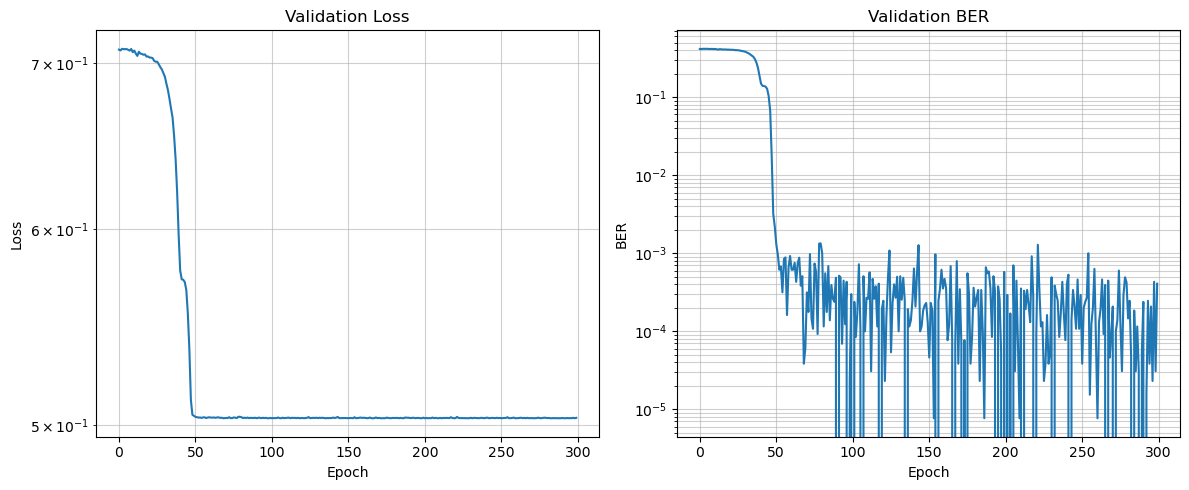

In [7]:

hierarchical_training()

In [8]:
# Evaluation

In [9]:
def evaluate_ko_performance(r, m, model_path, snr_range=None, test_batch_size=1000, num_examples=10000):
    """
    Evaluate KO code performance over a range of SNRs - simplified version
    
    Args:
        r, m: KO(m,r) code parameters
        model_path: Path to the folder containing trained model weights
        snr_range: List of SNR values to test
        test_batch_size: Batch size for testing
        num_examples: Total number of examples per SNR
        
    Returns:
        bers, blers: Lists of BER and BLER values for each SNR
    """
    print(f"Evaluating KO({m},{r}) performance...")
    
    if snr_range is None:
        snr_range = np.linspace(-2, 3, 6)
    
    # Load matrices for decoding
    Mul_Ind_Zero_dict, Mul_Ind_One_dict = first_order_Mul_matrices(device, m+1)
    
    # Code dimension
    code_dim_k = sum(math.comb(m, i) for i in range(r+1))
    print(f"Code parameters: k={code_dim_k}, n={2**m}")
    
    # Create model dictionaries
    gnet_dict = {}
    fnet_dict = {}
    
    # Get the hidden size used for training by peeking at the model file
    try:
        # Try to load one of the model files to determine hidden size
        encoder_state = torch.load(f'{model_path}/Models/best_Encoder_NN.pt')
        # Get any key to check the size
        any_key = next(iter(encoder_state.keys()))
        # Get fc1.weight to check its shape
        if 'fc1.weight' in encoder_state[any_key]:
            hidden_size = encoder_state[any_key]['fc1.weight'].shape[0]
            print(f"Detected hidden size: {hidden_size}")
        else:
            # Default to 120 if we can't determine
            hidden_size = 120
            print(f"Using default hidden size: {hidden_size}")
    except Exception as e:
        # If we can't load the file, default to 120 which is what was used in training
        hidden_size = 120
        print(f"Using default hidden size: {hidden_size} (Error loading model to detect: {str(e)})")
    
    # Initialize networks with the correct hidden size and no dropout for evaluation
    for i in range(3, m+1):
        gnet_dict[i] = g_Full(2, hidden_size, 1, dropout_rate=0).to(device)
        
    for i in range(1, 2*m-3):
        fnet_dict[i] = f_Full(2 if i % 2 == 1 else 4, hidden_size, 1, dropout_rate=0).to(device)
    
    # Load best model weights
    load_model_state(gnet_dict, fnet_dict, model_path, prefix='best_', m_max=m)
    
    # Set all models to evaluation mode
    for i in range(3, m+1):
        if i in gnet_dict:
            gnet_dict[i].eval()
            
    for i in range(1, 2*m-3):
        if i in fnet_dict:
            fnet_dict[i].eval()
    
    # Storage for results
    bers = []
    blers = []
    
    # Test at each SNR
    for snr in snr_range:
        print(f"Testing at SNR = {snr:.2f} dB")
        
        total_bit_errors = 0
        total_block_errors = 0
        
        num_batches = num_examples // test_batch_size
        
        # Process batches
        for batch in range(num_batches):
            # Progress indicator
            if batch % 5 == 0:
                print(f"  Batch {batch}/{num_batches}")
                
            # Generate random message bits
            msg_bits = 2*torch.randint(0, 2, (test_batch_size, code_dim_k), 
                                      dtype=torch.float32).to(device)-1
            
            with torch.no_grad():
                # Encode
                transmit_codewords = rm_encoder_plotkin_neural(msg_bits, r, m, gnet_dict)
                
                # Add noise
                noise_sigma = snr_db2sigma(snr)
                standard_gaussian = torch.randn_like(transmit_codewords)
                corrupted_codewords = transmit_codewords + noise_sigma * standard_gaussian
                llrs = (2/(noise_sigma**2)) * corrupted_codewords
                
                # Decode
                decoded_message = rm_decoder_dumer_neural(llrs, r, m, fnet_dict, gnet_dict, 
                                                        Mul_Ind_Zero_dict, Mul_Ind_One_dict)
                
                # Calculate errors
                bit_errors = torch.sum(msg_bits != decoded_message.sign()).item()
                block_errors = torch.sum(torch.any(msg_bits != decoded_message.sign(), dim=1)).item()
                
                total_bit_errors += bit_errors
                total_block_errors += block_errors
        
        # Calculate error rates
        ber = total_bit_errors / (num_examples * code_dim_k)
        bler = total_block_errors / num_examples
        
        print(f"SNR: {snr:.2f} dB, BER: {ber:.6f}, BLER: {bler:.6f}")
        
        bers.append(ber)
        blers.append(bler)
    
    # Print table of results
    print("\nSummary of KO code performance:")
    print("==============================")
    print(f"{'SNR (dB)':<10}{'BER':<15}{'BLER':<15}")
    print("------------------------------")
    for snr, ber, bler in zip(snr_range, bers, blers):
        print(f"{snr:<10.2f}{ber:<15.6f}{bler:<15.6f}")
    
    # Plot results
    plt.figure(figsize=(10, 6))
    plt.semilogy(snr_range, bers, 'bo-', linewidth=2, label='BER')
    plt.semilogy(snr_range, blers, 'ro-', linewidth=2, label='BLER')
    plt.grid(True)
    plt.xlabel('SNR (dB)')
    plt.ylabel('Error Rate')
    plt.title(f'KO({m},{r}) Performance')
    plt.legend()
    
    # Create directory to save results if it doesn't exist
    save_dir = os.path.join(model_path, 'evaluation')
    os.makedirs(save_dir, exist_ok=True)
    
    # Save plot
    plt.savefig(os.path.join(save_dir, f'ko_{m}_{r}_performance.png'))
    
    # Also save raw results
    results = {
        'snr_range': snr_range,
        'bers': bers,
        'blers': blers,
    }
    
    # Save to file
    with open(os.path.join(save_dir, f'ko_{m}_{r}_performance.pkl'), 'wb') as f:
        pickle.dump(results, f)
    
    print(f"\nPerformance plot and data saved to {save_dir}")
    
    return bers, blers



Evaluating KO(9,3) performance...
Code parameters: k=130, n=512
Detected hidden size: 120
Successfully loaded encoder g3
Successfully loaded encoder g4
Successfully loaded encoder g5
Successfully loaded encoder g6
Successfully loaded encoder g7
Successfully loaded encoder g8
Successfully loaded encoder g9
Successfully loaded decoder f1
Successfully loaded decoder f2
Successfully loaded decoder f3
Successfully loaded decoder f4
Successfully loaded decoder f5
Successfully loaded decoder f6
Successfully loaded decoder f7
Successfully loaded decoder f8
Successfully loaded decoder f9
Successfully loaded decoder f10
Successfully loaded decoder f11
Successfully loaded decoder f12
Successfully loaded decoder f13
Successfully loaded decoder f14
Testing at SNR = -6.00 dB
  Batch 0/1000
  Batch 5/1000
  Batch 10/1000
  Batch 15/1000
  Batch 20/1000
  Batch 25/1000
  Batch 30/1000
  Batch 35/1000
  Batch 40/1000
  Batch 45/1000
  Batch 50/1000
  Batch 55/1000
  Batch 60/1000
  Batch 65/1000
  Batc

  Batch 140/1000
  Batch 145/1000
  Batch 150/1000
  Batch 155/1000
  Batch 160/1000
  Batch 165/1000
  Batch 170/1000
  Batch 175/1000
  Batch 180/1000
  Batch 185/1000
  Batch 190/1000
  Batch 195/1000
  Batch 200/1000
  Batch 205/1000
  Batch 210/1000
  Batch 215/1000
  Batch 220/1000
  Batch 225/1000
  Batch 230/1000
  Batch 235/1000
  Batch 240/1000
  Batch 245/1000
  Batch 250/1000
  Batch 255/1000
  Batch 260/1000
  Batch 265/1000
  Batch 270/1000
  Batch 275/1000
  Batch 280/1000
  Batch 285/1000
  Batch 290/1000
  Batch 295/1000
  Batch 300/1000
  Batch 305/1000
  Batch 310/1000
  Batch 315/1000
  Batch 320/1000
  Batch 325/1000
  Batch 330/1000
  Batch 335/1000
  Batch 340/1000
  Batch 345/1000
  Batch 350/1000
  Batch 355/1000
  Batch 360/1000
  Batch 365/1000
  Batch 370/1000
  Batch 375/1000
  Batch 380/1000
  Batch 385/1000
  Batch 390/1000
  Batch 395/1000
  Batch 400/1000
  Batch 405/1000
  Batch 410/1000
  Batch 415/1000
  Batch 420/1000
  Batch 425/1000
  Batch 430/10

  Batch 525/1000
  Batch 530/1000
  Batch 535/1000
  Batch 540/1000
  Batch 545/1000
  Batch 550/1000
  Batch 555/1000
  Batch 560/1000
  Batch 565/1000
  Batch 570/1000
  Batch 575/1000
  Batch 580/1000
  Batch 585/1000
  Batch 590/1000
  Batch 595/1000
  Batch 600/1000
  Batch 605/1000
  Batch 610/1000
  Batch 615/1000
  Batch 620/1000
  Batch 625/1000
  Batch 630/1000
  Batch 635/1000
  Batch 640/1000
  Batch 645/1000
  Batch 650/1000
  Batch 655/1000
  Batch 660/1000
  Batch 665/1000
  Batch 670/1000
  Batch 675/1000
  Batch 680/1000
  Batch 685/1000
  Batch 690/1000
  Batch 695/1000
  Batch 700/1000
  Batch 705/1000
  Batch 710/1000
  Batch 715/1000
  Batch 720/1000
  Batch 725/1000
  Batch 730/1000
  Batch 735/1000
  Batch 740/1000
  Batch 745/1000
  Batch 750/1000
  Batch 755/1000
  Batch 760/1000
  Batch 765/1000
  Batch 770/1000
  Batch 775/1000
  Batch 780/1000
  Batch 785/1000
  Batch 790/1000
  Batch 795/1000
  Batch 800/1000
  Batch 805/1000
  Batch 810/1000
  Batch 815/10

  Batch 910/1000
  Batch 915/1000
  Batch 920/1000
  Batch 925/1000
  Batch 930/1000
  Batch 935/1000
  Batch 940/1000
  Batch 945/1000
  Batch 950/1000
  Batch 955/1000
  Batch 960/1000
  Batch 965/1000
  Batch 970/1000
  Batch 975/1000
  Batch 980/1000
  Batch 985/1000
  Batch 990/1000
  Batch 995/1000
SNR: 0.00 dB, BER: 0.000000, BLER: 0.000010
Testing at SNR = 1.00 dB
  Batch 0/1000
  Batch 5/1000
  Batch 10/1000
  Batch 15/1000
  Batch 20/1000
  Batch 25/1000
  Batch 30/1000
  Batch 35/1000
  Batch 40/1000
  Batch 45/1000
  Batch 50/1000
  Batch 55/1000
  Batch 60/1000
  Batch 65/1000
  Batch 70/1000
  Batch 75/1000
  Batch 80/1000
  Batch 85/1000
  Batch 90/1000
  Batch 95/1000
  Batch 100/1000
  Batch 105/1000
  Batch 110/1000
  Batch 115/1000
  Batch 120/1000
  Batch 125/1000
  Batch 130/1000
  Batch 135/1000
  Batch 140/1000
  Batch 145/1000
  Batch 150/1000
  Batch 155/1000
  Batch 160/1000
  Batch 165/1000
  Batch 170/1000
  Batch 175/1000
  Batch 180/1000
  Batch 185/1000
 

  Batch 280/1000
  Batch 285/1000
  Batch 290/1000
  Batch 295/1000
  Batch 300/1000
  Batch 305/1000
  Batch 310/1000
  Batch 315/1000
  Batch 320/1000
  Batch 325/1000
  Batch 330/1000
  Batch 335/1000
  Batch 340/1000
  Batch 345/1000
  Batch 350/1000
  Batch 355/1000
  Batch 360/1000
  Batch 365/1000
  Batch 370/1000
  Batch 375/1000
  Batch 380/1000
  Batch 385/1000
  Batch 390/1000
  Batch 395/1000
  Batch 400/1000
  Batch 405/1000
  Batch 410/1000
  Batch 415/1000
  Batch 420/1000
  Batch 425/1000
  Batch 430/1000
  Batch 435/1000
  Batch 440/1000
  Batch 445/1000
  Batch 450/1000
  Batch 455/1000
  Batch 460/1000
  Batch 465/1000
  Batch 470/1000
  Batch 475/1000
  Batch 480/1000
  Batch 485/1000
  Batch 490/1000
  Batch 495/1000
  Batch 500/1000
  Batch 505/1000
  Batch 510/1000
  Batch 515/1000
  Batch 520/1000
  Batch 525/1000
  Batch 530/1000
  Batch 535/1000
  Batch 540/1000
  Batch 545/1000
  Batch 550/1000
  Batch 555/1000
  Batch 560/1000
  Batch 565/1000
  Batch 570/10

([0.44832832307692305,
  0.3883161769230769,
  0.24126965384615384,
  0.0703116076923077,
  0.005927176923076923,
  9.981538461538462e-05,
  4.846153846153846e-07,
  0.0,
  0.0,
  0.0],
 [0.997403,
  0.958778,
  0.727366,
  0.283095,
  0.035574,
  0.000952,
  1e-05,
  0.0,
  0.0,
  0.0])

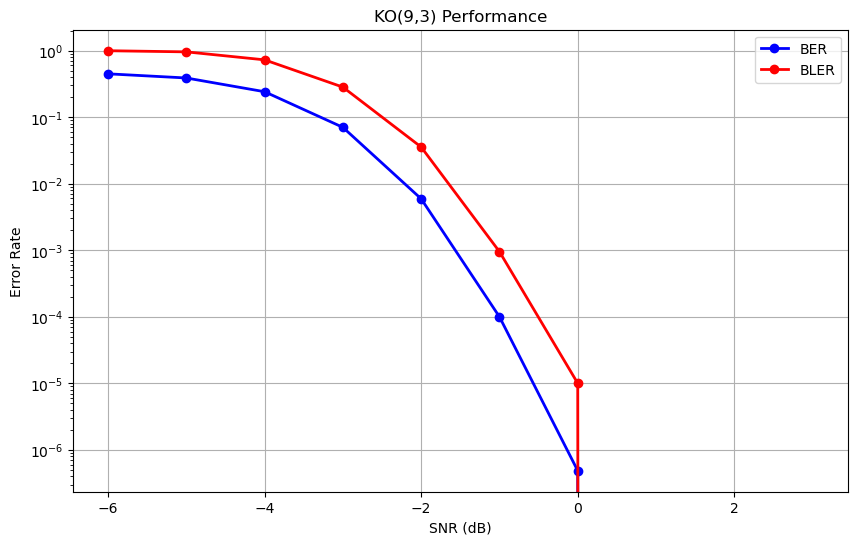

In [10]:
# After training, evaluate the KO(9,3) model
evaluate_ko_performance(
    r=3,  # KO(9,3)
    m=9,
    model_path='./Results/KO(9,3)_hierarchical_improved',
    snr_range=np.linspace(-6, 3, 10),
    test_batch_size=1000,
    num_examples=10**6
)

Summary of KO code performance:
==============================
SNR (dB)  BER            BLER           
------------------------------
-6.00     0.448328       0.997403       
-5.00     0.388316       0.958778       
-4.00     0.241270       0.727366       
-3.00     0.070312       0.283095       
-2.00     0.005927       0.035574       
-1.00     0.000100       0.000952       
0.00      0.000000       0.000010       
1.00      0.000000       0.000000       
2.00      0.000000       0.000000       
3.00      0.000000       0.000000 

In [11]:
def plot_pairwise_distances(r, m, model_path, num_codewords=1000):
    """
    Plot the pairwise distance distribution for KO code vs RM code vs Gaussian codebook
    
    Args:
        r, m: KO(m,r) code parameters
        model_path: Path to the folder containing trained model weights
        num_codewords: Number of codewords to generate for the distance analysis
    """
    print(f"Analyzing pairwise distances for KO({m},{r})...")
    
    # Load matrices for decoding
    Mul_Ind_Zero_dict, Mul_Ind_One_dict = first_order_Mul_matrices(device, m+1)
    
    # Code dimension
    code_dim_k = sum(math.comb(m, i) for i in range(r+1))
    n = 2**m  # Block length
    print(f"Code parameters: k={code_dim_k}, n={n}")
    
    # Create model dictionaries
    gnet_dict = {}
    fnet_dict = {}
    
    # Get hidden size from saved model
    try:
        encoder_state = torch.load(f'{model_path}/Models/best_Encoder_NN.pt')
        any_key = next(iter(encoder_state.keys()))
        if 'fc1.weight' in encoder_state[any_key]:
            hidden_size = encoder_state[any_key]['fc1.weight'].shape[0]
        else:
            hidden_size = 120
    except Exception as e:
        hidden_size = 120
        print(f"Using default hidden size: {hidden_size}")
    
    # Initialize networks
    for i in range(3, m+1):
        gnet_dict[i] = g_Full(2, hidden_size, 1, dropout_rate=0).to(device)
        
    for i in range(1, 2*m-3):
        fnet_dict[i] = f_Full(2 if i % 2 == 1 else 4, hidden_size, 1, dropout_rate=0).to(device)
    
    # Load best model weights
    load_model_state(gnet_dict, fnet_dict, model_path, prefix='best_', m_max=m)
    
    # Set models to evaluation mode
    for i in range(3, m+1):
        if i in gnet_dict:
            gnet_dict[i].eval()
    
    # Generate random message bits for testing
    all_msg_bits = 2 * (torch.rand(num_codewords, code_dim_k) < 0.5).float() - 1
    all_msg_bits = all_msg_bits.to(device)
    
    # Generate codewords for KO code, RM code, and random Gaussian
    with torch.no_grad():
        # KO code
        codebook_ko = rm_encoder_plotkin_neural(all_msg_bits, r, m, gnet_dict)
        
        # RM code
        codebook_rm = rm_encoder_plotkin(all_msg_bits, r, m)
        
        # KO code binarized (quantized to +/-1)
        codebook_ko_quantized = codebook_ko.sign()
        
        # Random Gaussian codebook with same power constraint
        Gaussian_codebook = F.normalize(torch.randn(num_codewords, n), p=2, dim=1) * np.sqrt(n)
    
    # Calculate pairwise distances
    def pairwise_distances(codebook):
        dists = []
        for row1, row2 in combinations(codebook.cpu(), 2): 
            distance = (row1-row2).pow(2).sum()
            dists.append(np.sqrt(distance.item()))
        return dists, np.min(dists)
    
    # Get distances for each codebook
    pairwise_dist_ko, d_min_ko = pairwise_distances(codebook_ko)
    pairwise_dist_ko_quantized, d_min_ko_quantized = pairwise_distances(codebook_ko_quantized)
    pairwise_dist_rm, d_min_rm = pairwise_distances(codebook_rm)
    pairwise_dist_Gaussian, d_min_Gaussian = pairwise_distances(Gaussian_codebook)
    
    total_pairwise_dist = len(pairwise_dist_ko)
    
    # Get min/max for consistent binning
    min_dist = min(np.min(pairwise_dist_ko), np.min(pairwise_dist_rm), np.min(pairwise_dist_Gaussian))
    max_dist = max(np.max(pairwise_dist_ko), np.max(pairwise_dist_rm), np.max(pairwise_dist_Gaussian))
    
    # Create histogram bins
    bins = np.linspace(min_dist, max_dist, 1000)
    
    # Calculate histograms
    n_ko, bins_ko = np.histogram(pairwise_dist_ko, bins=bins, density=True)
    n_ko_quantized, bins_ko_quantized = np.histogram(pairwise_dist_ko_quantized, bins=bins, density=False)
    n_rm, bins_rm = np.histogram(pairwise_dist_rm, bins=bins, density=False)
    n_Gaussian, bins_Gaussian = np.histogram(pairwise_dist_Gaussian, bins=bins, density=True)
    
    # Normalize count histograms
    n_rm = (1/total_pairwise_dist) * n_rm
    n_ko_quantized = (1/total_pairwise_dist) * n_ko_quantized
    
    # Create plot with more space at the bottom for the legend
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot the histograms
    rm_line, = plt.plot(bins_rm[:-1], n_rm, 
            label=f'RM({m},{r}): Min dist = {d_min_rm:.2f}', 
            linewidth=2.0)
    
    ko_line, = plt.plot(bins_ko[:-1], n_ko, 
            label=f'Hi-KO({m},{r}): Min dist = {d_min_ko:.2f}', 
            linewidth=2.0)
    
    ko_q_line, = plt.plot(bins_ko_quantized[:-1], n_ko_quantized, 
            label=f'Hi-KO({m},{r}) quantized: Min dist = {d_min_ko_quantized:.2f}', 
            linewidth=2.0)
    
    gauss_line, = plt.plot(bins_Gaussian[:-1], n_Gaussian, 
            label=f'Random Gaussian: Min dist = {d_min_Gaussian:.2f}', 
            linewidth=2.0)
    
    # Customize plot
    plt.xlabel("Pairwise distances", fontsize=16)
    plt.ylabel("Probability density", fontsize=16)
    plt.title(f"Hierarchical KO({m},{r})", fontsize=16)
    
    # Add major and minor grid lines
    plt.grid(True, which='both', linestyle='-', alpha=0.7)
    plt.minorticks_on()
    plt.grid(True, which='minor', linestyle=':', alpha=0.4)
    
    # Position the legend below the x-axis label
    plt.legend(
        handles=[rm_line, ko_line, ko_q_line, gauss_line],
        loc='upper center', 
        bbox_to_anchor=(0.5, -0.1),
        ncol=2,  # Display in 2 columns
        fontsize=16,
        frameon=True,
        fancybox=True,
        shadow=True
    )
    
    # Adjust layout to make room for the legend
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.2)  # Add extra space at the bottom
    
    # Save plot
    os.makedirs(os.path.join(model_path, 'analysis'), exist_ok=True)
    plt.savefig(os.path.join(model_path, 'analysis', f'pairwise_distances_KO({m},{r}).pdf'), format='pdf', bbox_inches='tight')
    plt.savefig(os.path.join(model_path, 'analysis', f'pairwise_distances_KO({m},{r}).png'), format='png', bbox_inches='tight')
    
    print(f"Pairwise distance plot saved to {os.path.join(model_path, 'analysis')}")
    
    # Save the histogram data
    np.savez(os.path.join(model_path, 'analysis', f'pairwise_distances_data_KO({m},{r}).npz'),
             ko_dist=pairwise_dist_ko,
             ko_quantized_dist=pairwise_dist_ko_quantized,
             rm_dist=pairwise_dist_rm,
             gaussian_dist=pairwise_dist_Gaussian,
             bins=bins,
             min_distances={
                 'ko': d_min_ko,
                 'ko_quantized': d_min_ko_quantized,
                 'rm': d_min_rm,
                 'gaussian': d_min_Gaussian
             })
    
    # Print minimum distances
    print(f"\nMinimum distances:")
    print(f"Hierarchical KO({m},{r}): {d_min_ko:.4f}")
    print(f"Quantized Hi-KO({m},{r}): {d_min_ko_quantized:.4f}")
    print(f"RM({m},{r}): {d_min_rm:.4f}")
    print(f"Random Gaussian: {d_min_Gaussian:.4f}")
    
    return fig



Analyzing pairwise distances for KO(9,3)...
Code parameters: k=130, n=512
Successfully loaded encoder g3
Successfully loaded encoder g4
Successfully loaded encoder g5
Successfully loaded encoder g6
Successfully loaded encoder g7
Successfully loaded encoder g8
Successfully loaded encoder g9
Successfully loaded decoder f1
Successfully loaded decoder f2
Successfully loaded decoder f3
Successfully loaded decoder f4
Successfully loaded decoder f5
Successfully loaded decoder f6
Successfully loaded decoder f7
Successfully loaded decoder f8
Successfully loaded decoder f9
Successfully loaded decoder f10
Successfully loaded decoder f11
Successfully loaded decoder f12
Successfully loaded decoder f13
Successfully loaded decoder f14
Pairwise distance plot saved to ./Results/KO(9,3)_hierarchical_improved/analysis

Minimum distances:
Hierarchical KO(9,3): 27.5273
Quantized Hi-KO(9,3): 28.0000
RM(9,3): 28.0000
Random Gaussian: 27.8364


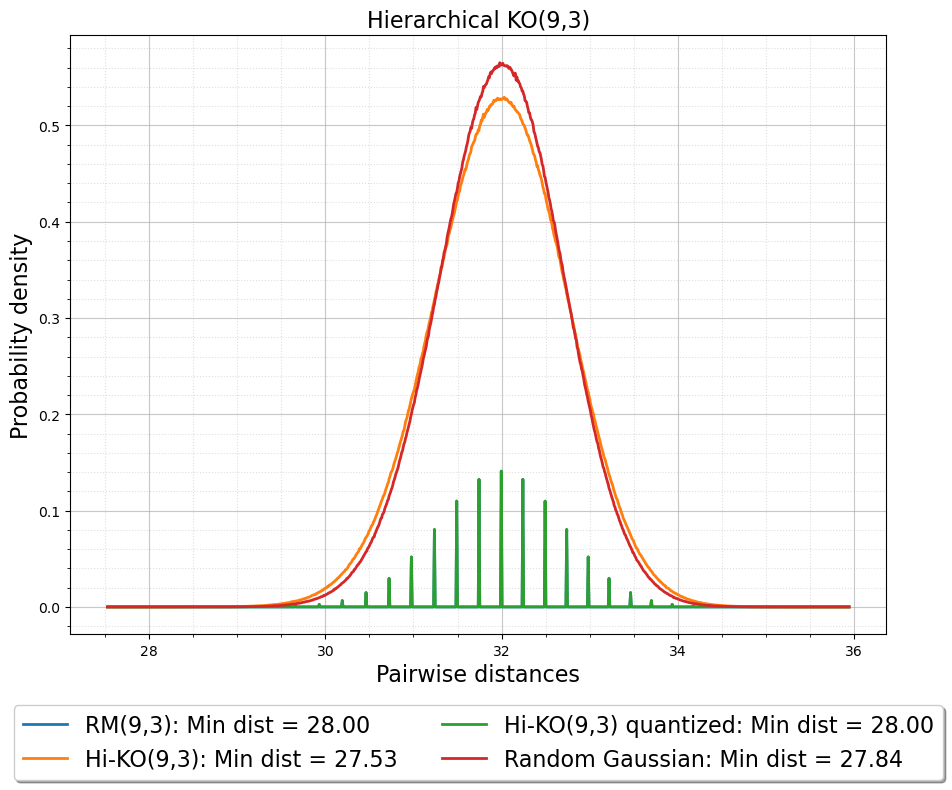

In [12]:
# Call the function to plot pairwise distances for KO(8,3)
r, m = 3, 9
model_path = './Results/KO(9,3)_hierarchical_improved'
fig = plot_pairwise_distances(r, m, model_path, num_codewords=10000)
plt.show()  # Show the plot in interactive environments